# VID:25 Normalization

The goal of normalization is to change the values of numeric columns in the dataset to use a common scale, without distorting differences in the rage of values or losing information

-> to eliminate units in numeric data, and evaluate all data in the same scale.

# *Min Max Scaling*

$$X_{norm} = \frac{X - X_{min}}{X_{max} - X_{min}}$$

after the conversion, the range for the value will be scaled in the range = [0,1]

In [9]:
import pandas as pd 
df = pd.read_csv('wine_data.csv', header=None, usecols=[0,1,2])
df.columns = ['Class label', 'Alcohol', 'Malic acid']
df

,Class label,Alcohol,Malic acid
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36
3,1,14.37,1.95
4,1,13.24,2.59
...,...,...,...
173,3,13.71,5.65
174,3,13.40,3.91
175,3,13.27,4.28
176,3,13.17,2.59


In [10]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df.drop('Class label', axis=1), df['Class label'], test_size=0.3, random_state=0)

In [11]:
X_train.shape, X_test.shape

((124, 2), (54, 2))

### fit the scaler to the ***train*** set, it will learn the parameters

In [12]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

scaler.fit(X_train)

#transform train and test sets 
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [14]:
X_test_scaled = pd.DataFrame(X_test_scaled, columns = X_test.columns)
X_train_scaled = pd.DataFrame(X_train_scaled, columns = X_train.columns)


In [17]:
import numpy as np
np.round(X_train.describe(), 1)

,Alcohol,Malic acid
count,124.0,124.0
mean,13.0,2.4
std,0.8,1.1
min,11.0,0.9
25%,12.4,1.6
50%,13.0,1.9
75%,13.6,3.2
max,14.8,5.6


In [18]:
np.round(X_train_scaled.describe(), 1)

,Alcohol,Malic acid
count,124.0,124.0
mean,0.5,0.3
std,0.2,0.2
min,0.0,0.0
25%,0.4,0.2
50%,0.5,0.2
75%,0.7,0.5
max,1.0,1.0


In [31]:
y_train

22     1
108    2
175    3
145    3
71     2
      ..
103    2
67     2
117    2
47     1
172    3
Name: Class label, Length: 124, dtype: int64

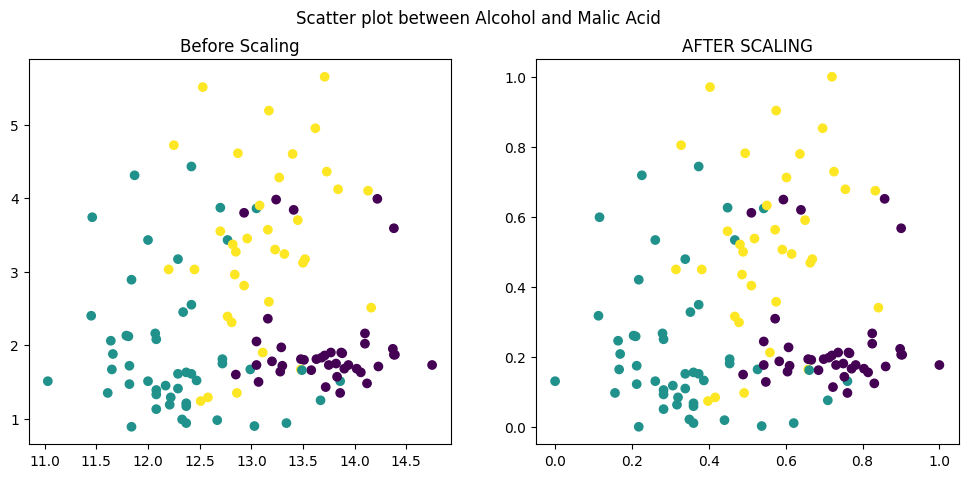

In [24]:
import matplotlib.pyplot as plt
fig, (ax1, ax2) = plt.subplots(ncols = 2, figsize = (12, 5))

ax1.scatter(X_train['Alcohol'], X_train['Malic acid'], c = y_train)
ax1.set_title("Before Scaling")
ax2.scatter(X_train_scaled['Alcohol'], X_train_scaled['Malic acid'], c = y_train)
ax2.set_title("AFTER SCALING")
fig.suptitle('Scatter plot between Alcohol and Malic Acid')
plt.show()

In [22]:
import seaborn as sns

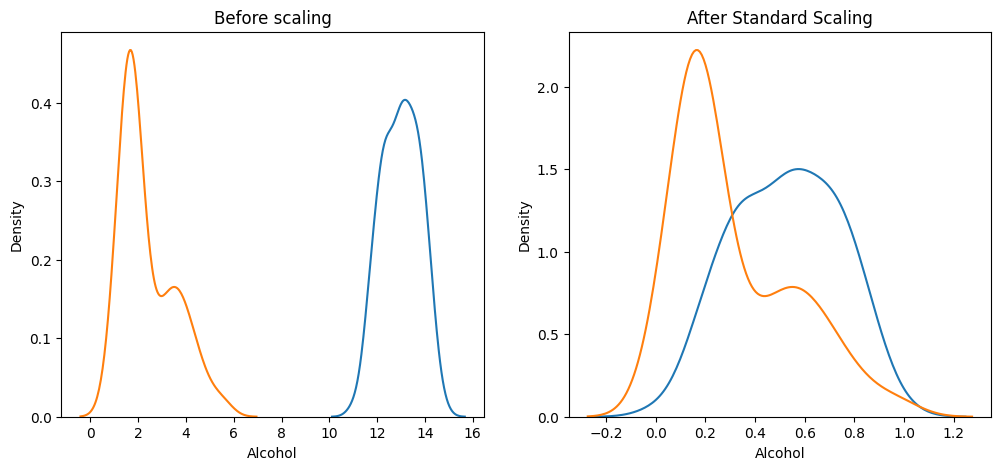

In [29]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))
ax1.set_title("Before scaling")
sns.kdeplot(X_train['Alcohol'], ax = ax1)
sns.kdeplot(X_train['Malic acid'], ax = ax1)

# after scaling
ax2.set_title('After Standard Scaling')
sns.kdeplot(X_train_scaled['Alcohol'], ax=ax2)
sns.kdeplot(X_train_scaled['Malic acid'], ax=ax2)
plt.show()

## Mean normalization

$$X_{norm} = \frac{X - \mu}{X_{max} - X_{min}}$$

Mean centering

-> rarely used, not supported in scikit 

## Max absolute scaling 

$$X_{scaled} = \frac{X}{|X_{max}|}$$

#### MaxAbsScaler() in scikitlearn
#### -> Used for sparse data(when there is higher frequency of null value)

## Robust scaling

$$X_{scaled} = \frac{X - Median}{IQR} = \frac{X - Q_2}{Q_3 - Q_1}$$

RobustScaler() in sklearn.preprocessing


# Normalization vs Standarization

1. Is feature scaling required?
2. Most of the problems are better with standarization. MinMax scaler is used when min and max of the numerical values.